# 04 — Modeling: Regression, Classification, Clustering

Input: `philly311_clean.csv`. Uses insights from notebook 03 (the fast/slow threshold,
which features to include). Fill in the marked spots based on your own EDA.

In [23]:
from google.colab import files
uploaded = files.upload()  # choose philly311_clean.csv

Saving philly311_clean.csv to philly311_clean (1).csv


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

TYPE_COL = "service_name"
ZIP_COL = "zipcode"
AGENCY_COL = "agency_responsible"

df = pd.read_csv("philly311_clean.csv", parse_dates=["requested_datetime", "closed_datetime"])
print(df.shape)

/tmp/ipykernel_947/4164299335.py:24: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("philly311_clean.csv", parse_dates=["requested_datetime", "closed_datetime"])


(252419, 30)


## Shared feature set

Same input features feed both regression and classification, so results are comparable.

In [25]:
categorical_features = [c for c in [ZIP_COL, "day_of_week"] if c in df.columns]
numeric_features = [c for c in ["hour_of_day", "month", "is_weekend"] if c in df.columns]

feature_cols = categorical_features + numeric_features
model_df = df.dropna(subset=feature_cols + ["resolution_hours", "log_resolution_hours"]).copy()
model_df[ZIP_COL] = (
    model_df[ZIP_COL]
    .astype(str)
    .str.strip()
    .str.split(r"[.\-]").str[0]   # keeps only the first part before "." or "-"
)
print(f"Rows usable for modeling: {len(model_df)} (dropped {len(df) - len(model_df)} with missing features)")

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), categorical_features),
    ("num", StandardScaler(), numeric_features),
])

Rows usable for modeling: 250898 (dropped 1521 with missing features)


# Part 1 — Regression: predict resolution time

In [26]:
X = model_df[feature_cols]
y_reg = model_df["log_resolution_hours"]

X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)

# Baseline
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

def report_regression(name, y_true, y_pred):
    # convert back from log scale to hours for interpretable error
    y_true_h = np.expm1(y_true)
    y_pred_h = np.expm1(y_pred)
    mae = mean_absolute_error(y_true_h, y_pred_h)
    rmse = mean_squared_error(y_true_h, y_pred_h) ** 0.5
    r2 = r2_score(y_true, y_pred)  # R2 on log scale, where the model is actually fit
    print(f"{name}: MAE={mae:.1f}h  RMSE={rmse:.1f}h  R2(log scale)={r2:.3f}")

report_regression("Baseline (median)", y_test, baseline_pred)

Baseline (median): MAE=4789.3h  RMSE=8168.3h  R2(log scale)=-0.001


In [27]:
lin_model = Pipeline([("prep", preprocessor), ("reg", LinearRegression())])
lin_model.fit(X_train, y_train)
report_regression("Linear Regression", y_test, lin_model.predict(X_test))

rf_model = Pipeline([("prep", preprocessor), ("reg", RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1))])
rf_model.fit(X_train, y_train)
report_regression("Random Forest", y_test, rf_model.predict(X_test))

Linear Regression: MAE=4675.5h  RMSE=8083.5h  R2(log scale)=0.046
Random Forest: MAE=4695.9h  RMSE=8095.0h  R2(log scale)=0.060


In [28]:
# Feature importance from the random forest (post-encoding names)
feature_names = rf_model.named_steps["prep"].get_feature_names_out()
importances = rf_model.named_steps["reg"].feature_importances_
importance_df = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
importance_df.head(15)

,feature,importance
54,num__hour_of_day,0.301580
55,num__month,0.219678
5,cat__zipcode_19111,0.060099
25,cat__zipcode_19134,0.031160
56,num__is_weekend,0.030501
15,cat__zipcode_19124,0.024113
14,cat__zipcode_19123,0.022409
51,cat__day_of_week_Thursday,0.021348
48,cat__day_of_week_Monday,0.020152
4,cat__zipcode_19107,0.019674


**Interpret, don't just report:** does the top-importance list match what you saw in
notebook 03's EDA? If R² is low, that's a legitimate finding — say what it implies
(e.g. resolution time may depend on factors not captured here, like crew scheduling).

# Part 2 — Classification: fast vs. slow

In [29]:
# Threshold: default to the median from your EDA. Change FAST_THRESHOLD_HOURS if you
# picked a domain-meaningful cutoff instead (e.g. 168 hours = 7 days) and justify it in your report.
FAST_THRESHOLD_HOURS = model_df["resolution_hours"].median()
print(f"Using threshold: {FAST_THRESHOLD_HOURS:.1f} hours ({FAST_THRESHOLD_HOURS/24:.1f} days)")

model_df["is_slow"] = (model_df["resolution_hours"] > FAST_THRESHOLD_HOURS).astype(int)
y_clf = model_df["is_slow"]
print(model_df["is_slow"].value_counts(normalize=True))

Using threshold: 3158.7 hours (131.6 days)
is_slow
0    0.5
1    0.5
Name: proportion, dtype: float64


In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

def report_classification(name, y_true, y_pred):
    print(f"{name}: acc={accuracy_score(y_true, y_pred):.3f}  "
          f"precision={precision_score(y_true, y_pred):.3f}  "
          f"recall={recall_score(y_true, y_pred):.3f}  "
          f"f1={f1_score(y_true, y_pred):.3f}")

baseline_clf = DummyClassifier(strategy="most_frequent")
baseline_clf.fit(X_train, y_train)
report_classification("Baseline (majority class)", y_test, baseline_clf.predict(X_test))

logit = Pipeline([("prep", preprocessor), ("clf", LogisticRegression(max_iter=1000))])
logit.fit(X_train, y_train)
report_classification("Logistic Regression", y_test, logit.predict(X_test))

rf_clf = Pipeline([("prep", preprocessor), ("clf", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1))])
rf_clf.fit(X_train, y_train)
rf_clf_pred = rf_clf.predict(X_test)
report_classification("Random Forest", y_test, rf_clf_pred)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Baseline (majority class): acc=0.500  precision=0.000  recall=0.000  f1=0.000
Logistic Regression: acc=0.597  precision=0.595  recall=0.608  f1=0.602
Random Forest: acc=0.597  precision=0.589  recall=0.639  f1=0.613


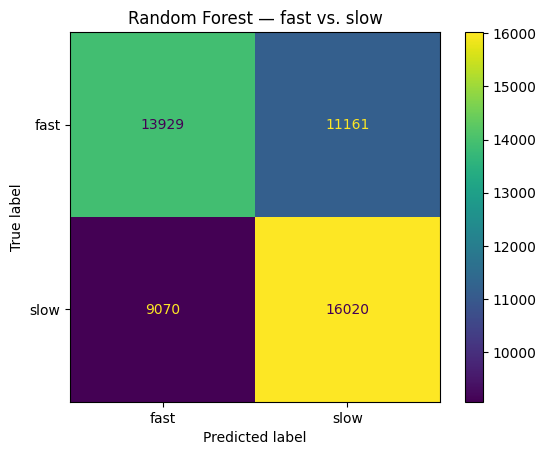

In [31]:
cm = confusion_matrix(y_test, rf_clf_pred)
ConfusionMatrixDisplay(cm, display_labels=["fast", "slow"]).plot()
plt.title("Random Forest — fast vs. slow")
plt.show()

# Part 3 — Clustering

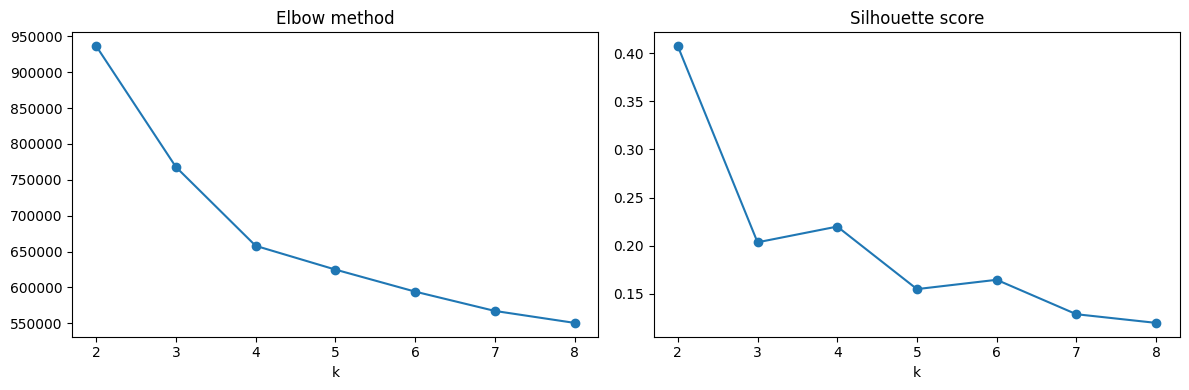

In [32]:
# Decide: include resolution_hours as a clustering feature, or exclude it to find
# clusters independent of outcome? Default here EXCLUDES it (clusters describe request
# *profile*; you then check how resolution time varies across the resulting clusters).
cluster_features = feature_cols
X_cluster = model_df[cluster_features]

X_cluster_encoded = preprocessor.fit_transform(X_cluster)

inertias, silhouettes = [], []
k_range = range(2, 9)
sample = np.random.RandomState(42).choice(X_cluster_encoded.shape[0], size=min(5000, X_cluster_encoded.shape[0]), replace=False)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_encoded)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster_encoded[sample], labels[sample]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[1].plot(list(k_range), silhouettes, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [33]:
# Pick K based on the plots above
K = 4  # <-- change based on elbow/silhouette results

kmeans_final = KMeans(n_clusters=K, random_state=42, n_init=10)
model_df["cluster"] = kmeans_final.fit_predict(X_cluster_encoded)

cluster_summary = model_df.groupby("cluster").agg(
    n=("cluster", "size"),
    median_resolution_hours=("resolution_hours", "median"),
    top_type=(TYPE_COL, lambda s: s.mode()[0] if not s.mode().empty else None),
    top_agency=(AGENCY_COL, lambda s: s.mode()[0] if not s.mode().empty else None) if AGENCY_COL in model_df.columns else ("cluster", "size"),
)
cluster_summary

,n,median_resolution_hours,top_type,top_agency
cluster,,,,
0,17420,2893.883750,Abandoned Vehicle,Police Department
1,108712,2803.495694,Abandoned Vehicle,Police Department
2,100112,3503.849167,Abandoned Vehicle,Police Department
3,24654,3421.681944,Abandoned Vehicle,Police Department


**For each cluster, write one sentence describing it in plain language** — e.g.
"Cluster 1: weekday requests in [agency], resolved quickly (median X hours), concentrated
in [area]." This description, not the algorithm mechanics, is what belongs in your report.

In [34]:
cluster_summary2 = model_df.groupby("cluster").agg(
    n=("cluster", "size"),
    median_resolution_hours=("resolution_hours", "median"),
    top_zip=(ZIP_COL, lambda s: s.mode()[0] if not s.mode().empty else None),
    avg_hour=("hour_of_day", "mean"),
    pct_weekend=("is_weekend", "mean"),
)
cluster_summary2

,n,median_resolution_hours,top_zip,avg_hour,pct_weekend
cluster,,,,,
0,17420,2893.883750,19143,2.687658,0.0
1,108712,2803.495694,19124,16.805293,0.0
2,100112,3503.849167,19124,16.655356,0.0
3,24654,3421.681944,19120,14.458181,1.0
